# Priority Queues & `heapq`

A **Priority Queue** is an abstract data type (ADT) supporting:
- `insert(key, value)` — add an element with a priority key
- `peek_min()` / `peek_max()` — inspect the highest-priority element in $O(1)$
- `extract_min()` / `extract_max()` — remove and return it in $O(\log n)$

A **binary heap** is the standard concrete implementation of a priority queue.

## Binary Heap Properties
1. **Complete Binary Tree:** Every level is completely filled except possibly the last, which is filled left-to-right -> height is guaranteed to be $\lfloor \log_2 n \rfloor = O(\log n)$.
2. **Heap-Order Property:**
   - **Min-heap:** Every node's key $\le$ its children's keys (`heap[0]` is the minimum).
   - **Max-heap:** Every node's key $\ge$ its children's keys (`heap[0]` is the maximum).

> **Heap vs. Binary Search Tree (BST):** Heaps impose **no** ordering between siblings and do not maintain full sorted order across levels — only parent-child ordering. In return, they fit compactly in a flat array with no pointer overhead!

### Array Storage Layout (0-indexed)
For any node at index $i$:
- **Parent:** $\lfloor (i - 1) / 2 \rfloor$
- **Left child:** $2i + 1$
- **Right child:** $2i + 2$

```
Tree view (min-heap):             Array view:
          1                       index:  0   1   2   3   4   5
        /   \                     value: [1,  3,  2,  7,  6,  5]
       3     2
      / \   /
     7   6 5
```

---

## Python's `heapq` Module

- `heapq` **always implements a min-heap**. For a numeric max-heap, store negated keys (`-priority`).
- `heapq` operates directly on a **regular Python `list`** maintaining the invariant:
  $$\text{heap}[k] \le \text{heap}[2k + 1] \quad \text{and} \quad \text{heap}[k] \le \text{heap}[2k + 2]$$
- `heap[0]` is always the smallest item ($O(1)$), and any sorted list already satisfies the min-heap invariant.

In [1]:
import heapq

# Building a min-heap with heappush: O(log n) per push
min_heap = []
for x in [4, 1, 3, 2]:
    heapq.heappush(min_heap, x)
print("min_heap:", min_heap, "| smallest:", min_heap[0])

# Simulating a max-heap by negating numeric keys
max_heap = []
for x in [4, 1, 3, 2]:
    heapq.heappush(max_heap, -x)
print("max_heap (un-negated):", [-k for k in max_heap], "| largest:", -max_heap[0])

min_heap: [1, 2, 3, 4] | smallest: 1
max_heap (un-negated): [4, 2, 3, 1] | largest: 4


---
## 1. `heapify()` — $O(n)$ Linear-Time Construction

Calling `heapq.heapify(data)` converts an existing list into a valid min-heap **in-place in $O(n)$ time** using **Floyd's bottom-up sift-down algorithm**.

Why $O(n)$ instead of $O(n \log n)$? Half the nodes are leaves (height 0 -> 0 work), a quarter have height 1, an eighth have height 2, etc.:
$$\sum_{h=0}^{\lfloor \log_2 n \rfloor} \frac{n}{2^{h+1}} \cdot O(h) = O(n)$$
By contrast, pushing $n$ elements one by one with `heappush` takes $O(n \log n)$.

In [2]:
data = [3, 1, 4, 2, 5]
heapq.heapify(data)  # in-place O(n)
print("heapified:", data)

# Peek O(1) vs Pop O(log n)
print("peek min (O(1)):", data[0])
smallest = heapq.heappop(data)  # O(log n)
print("popped:", smallest, "| remaining heap:", data)

heapified: [1, 2, 4, 3, 5]
peek min (O(1)): 1
popped: 1 | remaining heap: [2, 3, 4, 5]


---
## 2. `heappushpop()` vs. `heapreplace()`

Both run in $O(\log n)$ with a **single** sift operation (faster than separate `heappush` + `heappop`).
- **`heappushpop(heap, item)`**: pushes `item`, *then* pops and returns the smallest item (can return `item` itself if `item <= heap[0]`).
- **`heapreplace(heap, item)`**: pops and returns the current smallest item *first*, *then* pushes `item` (heap must be non-empty; returned item may be larger than `item`).

> **Critical rule:** The list **must already be a valid heap** (`heapify` first!) before calling `heappushpop` or `heapreplace` — otherwise `heap[0]` is not guaranteed to be the minimum!

In [3]:
# Always heapify before using heappushpop / heapreplace!
h1 = [5, 1, 3]
heapq.heapify(h1)  # -> [1, 5, 3]
popped_1 = heapq.heappushpop(h1, 0)
print("heappushpop([1, 5, 3], 0) -> popped:", popped_1, "| heap:", h1)

h2 = [5, 1, 3]
heapq.heapify(h2)  # -> [1, 5, 3]
popped_2 = heapq.heapreplace(h2, 0)
print("heapreplace([1, 5, 3], 0) -> popped:", popped_2, "| heap:", h2)

heappushpop([1, 5, 3], 0) -> popped: 0 | heap: [1, 5, 3]
heapreplace([1, 5, 3], 0) -> popped: 1 | heap: [0, 5, 3]


---
## 3. Heapsort & Tie-Breaking Gotcha

Heapsort extracts elements in sorted order in $O(n \log n)$ time (not stable).

> **Python Tuple Tie-Breaking Gotcha:** If you push `(priority, payload)` tuples and two items share the same `priority`, Python compares `payload` next. If `payload` is a `dict` or custom non-orderable object, Python raises **`TypeError: '<' not supported between instances of 'dict' and 'dict'`**.
> **Fix:** Include a monotonic tie-breaker `(priority, seq, payload)` (using `itertools.count()`) or use `@dataclass(order=True)` with `field(compare=False)`.

In [4]:
from dataclasses import dataclass, field
from itertools import count


def heapsort(iterable):
    h = list(iterable)
    heapq.heapify(h)  # O(n)
    return [heapq.heappop(h) for _ in range(len(h))]  # O(n log n)


print("heapsort numbers:", heapsort([3, 1, 4, 2, 5]))

# Tie-breaking with incomparable dict payloads
bad_heap = []
heapq.heappush(bad_heap, (1, {"task": "train"}))
try:
    heapq.heappush(bad_heap, (1, {"task": "eval"}))
except TypeError as e:
    print("Without tie-breaker -> TypeError:", e)

# Fix 1: monotonic counter (also makes equal priorities FIFO!)
counter = count()
safe_heap = []
for prio, task in [(2, {"task": "deploy"}), (1, {"task": "train"}), (1, {"task": "eval"})]:
    heapq.heappush(safe_heap, (prio, next(counter), task))
print("With counter tie-breaker:", [heapq.heappop(safe_heap)[2] for _ in range(len(safe_heap))])


# Fix 2: @dataclass(order=True) with field(compare=False)
@dataclass(order=True)
class PrioritizedTask:
    priority: int
    seq: int
    payload: dict = field(compare=False)


dc_heap = []
for seq, (prio, payload) in enumerate([(2, {"name": "C"}), (1, {"name": "A"}), (1, {"name": "B"})]):
    heapq.heappush(dc_heap, PrioritizedTask(prio, seq, payload))
print("With dataclass:", [heapq.heappop(dc_heap).payload["name"] for _ in range(len(dc_heap))])

heapsort numbers: [1, 2, 3, 4, 5]
Without tie-breaker -> TypeError: '<' not supported between instances of 'dict' and 'dict'
With counter tie-breaker: [{'task': 'train'}, {'task': 'eval'}, {'task': 'deploy'}]
With dataclass: ['A', 'B', 'C']


---
## 4. `heapq.merge()`, `nlargest()`, and `nsmallest()`

- **`heapq.merge(*iterables, key=None, reverse=False)`**: lazily merges $k$ **already-sorted** iterables in $O(n \log k)$ time and $O(k)$ memory (returns an iterator).
- **`heapq.nlargest(k, iterable, key=None)`** / **`heapq.nsmallest(k, iterable, key=None)`**: $O(n \log k)$ time and $O(k)$ memory.
  - Best when **$k \ll n$**.
  - When $k = 1$, use built-in `min()` / `max()` ($O(n)$).
  - When $k \approx n$, `sorted(iterable)[:k]` is faster in CPython (Timsort in C).

In [5]:
# Lazy k-way merge of sorted streams
merged = heapq.merge([1, 4, 7], [2, 5, 8], [3, 6, 9])
print("heapq.merge:", list(merged))

# Reverse merge of descending streams
desc = heapq.merge([9, 5, 1], [8, 6, 2], reverse=True)
print("heapq.merge(reverse=True):", list(desc))

# nlargest & nsmallest with key=
models = [
    {"name": "model_a", "f1": 0.87},
    {"name": "model_b", "f1": 0.93},
    {"name": "model_c", "f1": 0.91},
    {"name": "model_d", "f1": 0.82},
]
print("Top 2 models by F1:", [m["name"] for m in heapq.nlargest(2, models, key=lambda m: m["f1"])])
print("Bottom 2 models by F1:", [m["name"] for m in heapq.nsmallest(2, models, key=lambda m: m["f1"])])

heapq.merge: [1, 2, 3, 4, 5, 6, 7, 8, 9]
heapq.merge(reverse=True): [9, 8, 6, 5, 2, 1]
Top 2 models by F1: ['model_b', 'model_c']
Bottom 2 models by F1: ['model_d', 'model_a']


---
## 5. Two Classic Production / Interview Patterns

### Pattern A: Lazy Deletion (Updating Priorities in $O(\log n)$)
`heapq` does not provide an $O(\log n)$ `decrease_key` or arbitrary `remove`. The standard pattern is **lazy deletion**: push the updated `(new_priority, item)` onto the heap and record the latest valid priority in a `dict`, discarding stale entries when popped.

### Pattern B: Streaming Running Median (Two Heaps)
Maintain a **max-heap** (`low`) for the smaller half and a **min-heap** (`high`) for the larger half, balanced so `len(low) == len(high)` or `len(low) == len(high) + 1`. Each insertion is $O(\log n)$ and median lookup is $O(1)$.

In [6]:
# Pattern A: Lazy Deletion Priority Queue
class UpdatableMinHeap:
    def __init__(self):
        self._heap = []
        self._latest = {}

    def push_or_update(self, item, priority):
        self._latest[item] = priority
        heapq.heappush(self._heap, (priority, item))

    def remove(self, item):
        self._latest.pop(item, None)

    def pop(self):
        while self._heap:
            prio, item = heapq.heappop(self._heap)
            if self._latest.get(item) == prio:
                del self._latest[item]
                return item, prio
        raise KeyError("pop from empty priority queue")


pq = UpdatableMinHeap()
pq.push_or_update("job_a", 5)
pq.push_or_update("job_b", 3)
pq.push_or_update("job_a", 1)  # update priority of job_a from 5 -> 1
pq.remove("job_b")
print("Popped from UpdatableMinHeap:", pq.pop())


# Pattern B: Running Median with Two Heaps
class RunningMedian:
    def __init__(self):
        self.low = []   # max-heap (stored negated)
        self.high = []  # min-heap

    def add(self, num: float) -> None:
        heapq.heappush(self.low, -num)
        heapq.heappush(self.high, -heapq.heappop(self.low))
        if len(self.high) > len(self.low):
            heapq.heappush(self.low, -heapq.heappop(self.high))

    def median(self) -> float:
        if len(self.low) > len(self.high):
            return float(-self.low[0])
        return (-self.low[0] + self.high[0]) / 2.0


rm = RunningMedian()
stream = [5, 15, 1, 3, 8, 7]
medians = []
for val in stream:
    rm.add(val)
    medians.append(rm.median())
print("Stream: ", stream)
print("Medians:", medians)

Popped from UpdatableMinHeap: ('job_a', 1)
Stream:  [5, 15, 1, 3, 8, 7]
Medians: [5.0, 10.0, 5.0, 4.0, 5.0, 6.0]


---
## 6. Case Study & Fair Benchmark: Finding $k$ Closest Points to the Origin

Compare four approaches to find the $k$ closest points to $(0, 0)$ out of $n$ points.
Notice we use squared distance $d^2 = x^2 + y^2$ across **all** approaches (since $\sqrt{\cdot}$ is strictly monotonic, omitting `math.sqrt` is both exact and an apples-to-apples benchmark).

| Approach | Time Complexity | Extra Space | When It Wins |
|---|---|---|---|
| **Max-Heap of size $k$** (manual or `heapq.nsmallest`) | $O(n \log k)$ | $O(k)$ | Small $k \ll n$ (especially streaming!) |
| **Min-Heap (`heapify` + $k$ pops)** | $O(n + k \log n)$ | $O(n)$ | Small-to-moderate $k$ when data is already in memory |
| **Timsort (`sorted()[:k]`)** | $O(n \log n)$ | $O(n)$ | Large $k$ (CPython's C Timsort has very low constant factors) |

All 4 implementations match on sanity check!
k=     10 -> Min-Heap:   47.7ms | Max-Heap:    9.1ms | nsmallest:    9.9ms | Timsort:   37.8ms   [fastest: Max-Heap]
k=     50 -> Min-Heap:   48.8ms | Max-Heap:    9.3ms | nsmallest:    9.9ms | Timsort:   38.8ms   [fastest: Max-Heap]
k=    200 -> Min-Heap:   50.3ms | Max-Heap:    9.3ms | nsmallest:   10.0ms | Timsort:   37.4ms   [fastest: Max-Heap]
k=  1,000 -> Min-Heap:   51.1ms | Max-Heap:   10.9ms | nsmallest:   11.6ms | Timsort:   38.7ms   [fastest: Max-Heap]
k=  5,000 -> Min-Heap:   55.9ms | Max-Heap:   17.7ms | nsmallest:   17.7ms | Timsort:   38.3ms   [fastest: Max-Heap]
k= 25,000 -> Min-Heap:   77.3ms | Max-Heap:   39.3ms | nsmallest:   42.8ms | Timsort:   39.6ms   [fastest: Max-Heap]
k=100,000 -> Min-Heap:  152.1ms | Max-Heap:   86.6ms | nsmallest:   96.8ms | Timsort:   38.7ms   [fastest: Timsort]


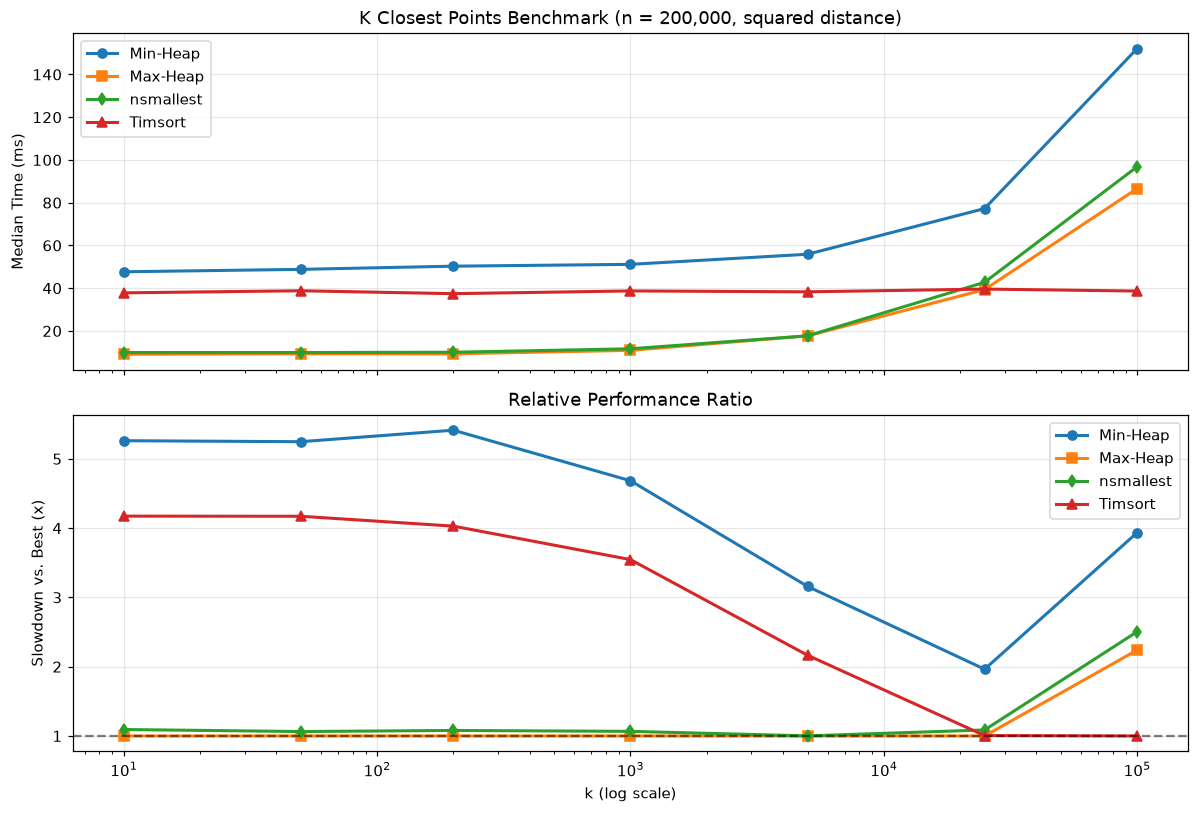

In [7]:
import random
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np


def k_closest_min_heap(points, k):
    min_heap = [(x * x + y * y, (x, y)) for x, y in points]
    heapq.heapify(min_heap)  # O(n)
    return [heapq.heappop(min_heap)[1] for _ in range(min(k, len(min_heap)))]  # O(k log n)


def k_closest_max_heap(points, k):
    if k >= len(points):
        return list(points)
    max_heap = []
    for x, y in points:
        neg_d2 = -(x * x + y * y)
        if len(max_heap) < k:
            heapq.heappush(max_heap, (neg_d2, (x, y)))
        elif neg_d2 > max_heap[0][0]:
            heapq.heappushpop(max_heap, (neg_d2, (x, y)))
    return [pt for _, pt in max_heap]


def k_closest_nsmallest(points, k):
    return heapq.nsmallest(k, points, key=lambda p: p[0] * p[0] + p[1] * p[1])


def k_closest_sorting(points, k):
    return sorted(points, key=lambda p: p[0] * p[0] + p[1] * p[1])[:k]


# Quick correctness sanity check
sample_pts = [(3, 3), (5, -1), (-2, 4), (1, 1), (0, 2)]
expected = {(1, 1), (0, 2)}
assert set(k_closest_min_heap(sample_pts, 2)) == expected
assert set(k_closest_max_heap(sample_pts, 2)) == expected
assert set(k_closest_nsmallest(sample_pts, 2)) == expected
assert set(k_closest_sorting(sample_pts, 2)) == expected
print("All 4 implementations match on sanity check!")


def time_median(func, *args, trials=3):
    times = []
    for _ in range(trials):
        t0 = perf_counter()
        func(*args)
        times.append(perf_counter() - t0)
    return float(np.median(times))


rng = random.Random(42)
n = 200_000
points = [(rng.uniform(-1000, 1000), rng.uniform(-1000, 1000)) for _ in range(n)]
k_values = [10, 50, 200, 1_000, 5_000, 25_000, 100_000]

results = {name: [] for name in ["Min-Heap", "Max-Heap", "nsmallest", "Timsort"]}
funcs = {
    "Min-Heap": k_closest_min_heap,
    "Max-Heap": k_closest_max_heap,
    "nsmallest": k_closest_nsmallest,
    "Timsort": k_closest_sorting,
}

for k in k_values:
    for name, fn in funcs.items():
        results[name].append(time_median(fn, points, k, trials=3))
    fastest = min(results, key=lambda name: results[name][-1])
    row = " | ".join(f"{name}: {results[name][-1]*1000:6.1f}ms" for name in funcs)
    print(f"k={k:>7,} -> {row}   [fastest: {fastest}]")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True)
styles = {"Min-Heap": "o-", "Max-Heap": "s-", "nsmallest": "d-", "Timsort": "^-"}
for name, times in results.items():
    ax1.plot(k_values, [t * 1000 for t in times], styles[name], label=name, linewidth=2)
ax1.set_xscale("log")
ax1.set_ylabel("Median Time (ms)")
ax1.set_title(f"K Closest Points Benchmark (n = {n:,}, squared distance)")
ax1.legend()
ax1.grid(True, alpha=0.3)

best = np.minimum.reduce(list(results.values()))
for name, times in results.items():
    ax2.plot(k_values, np.array(times) / best, styles[name], label=name, linewidth=2)
ax2.axhline(1.0, color="black", linestyle="--", alpha=0.5)
ax2.set_xscale("log")
ax2.set_xlabel("k (log scale)")
ax2.set_ylabel("Slowdown vs. Best (x)")
ax2.set_title("Relative Performance Ratio")
ax2.legend()
ax2.grid(True, alpha=0.3)
fig.tight_layout()